# Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# LOAD DATA

In [2]:
patients = pd.read_csv(r"C:\Users\priyanka\Desktop\Uploads\patients.csv")
visits = pd.read_csv(r"C:\Users\priyanka\Desktop\Uploads\visits.csv")
billing = pd.read_csv(r"C:\Users\priyanka\Desktop\Uploads\billing.csv")

In [3]:
df = pd.merge(visits, patients, on="patient_id", how="inner")

In [4]:
df = pd.merge(df, billing, on="visit_id", how="left")

The three datasets (patients, visits, and billing) were combined using relational joins.
Patients were joined with visits using patient_id, and the resulting dataset was further joined with billing using visit_id.
A left join was used for billing to retain all visit records, even if billing information was missing.

In [5]:
df.head()
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   visit_id              25000 non-null  int64  
 1   patient_id            25000 non-null  int64  
 2   visit_date            25000 non-null  object 
 3   department            25000 non-null  object 
 4   visit_type            25000 non-null  object 
 5   length_of_stay_hours  25000 non-null  float64
 6   risk_score            25000 non-null  object 
 7   doctor_id             25000 non-null  int64  
 8   age                   25000 non-null  int64  
 9   gender                25000 non-null  object 
 10  city                  25000 non-null  object 
 11  insurance_provider    25000 non-null  object 
 12  chronic_flag          25000 non-null  int64  
 13  registration_date     25000 non-null  object 
 14  bill_id               25000 non-null  int64  
 15  billed_amount      

,visit_id,patient_id,length_of_stay_hours,doctor_id,age,chronic_flag,bill_id,billed_amount,approved_amount,payment_days
count,25000.000000,25000.00000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,23682.000000,24210.000000
mean,12500.500000,2509.51536,19.551584,150.172400,44.768320,0.502600,12500.500000,20870.757442,16348.107777,13.048079
std,7217.022701,1448.68904,12.314004,29.135796,17.784232,0.500003,7217.022701,12606.285782,13778.804779,7.237736
min,1.000000,1.00000,0.500000,100.000000,1.000000,0.000000,1.000000,500.000000,0.000000,1.000000
25%,6250.750000,1249.00000,9.960000,125.000000,33.000000,0.000000,6250.750000,11582.450000,4603.070000,8.000000
50%,12500.500000,2505.00000,18.205000,151.000000,45.000000,1.000000,12500.500000,19644.850000,14379.645000,13.000000
75%,18750.250000,3764.00000,27.312500,175.000000,57.000000,1.000000,18750.250000,28398.065000,24845.020000,17.000000
max,25000.000000,5000.00000,78.420000,200.000000,90.000000,1.000000,25000.000000,88539.010000,88539.010000,55.000000


High-risk patients are likely associated with higher age, chronic conditions, and emergency visits
Hospitals lose revenue due to gap between billed and approved amounts
Missing approved amounts indicate pending or rejected claims
Departments like ICU contribute more to high-risk cases
Long payment days indicate insurance processing delays
Doctor-level analysis helps in resource optimization

# MISSING VALUE

In [6]:
df.isnull().sum()

visit_id                   0
patient_id                 0
visit_date                 0
department                 0
visit_type                 0
length_of_stay_hours       0
risk_score                 0
doctor_id                  0
age                        0
gender                     0
city                       0
insurance_provider         0
chronic_flag               0
registration_date          0
bill_id                    0
billed_amount              0
approved_amount         1318
claim_status               0
payment_days             790
billing_date               0
dtype: int64

In [7]:
df[['approved_amount','payment_days','length_of_stay_hours']].isnull().sum()

approved_amount         1318
payment_days             790
length_of_stay_hours       0
dtype: int64

# Distribution analysis
Department distribution

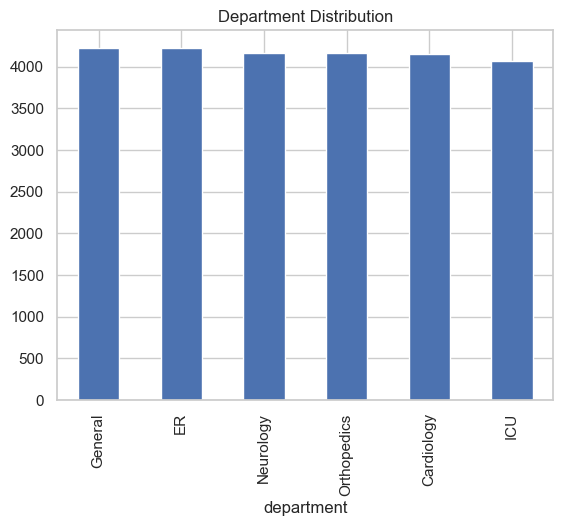

In [8]:
plt.figure()
df['department'].value_counts().plot(kind='bar')
plt.title("Department Distribution")
plt.show()